# TODO change this to be appropriate for my files
# TODO also check and make sure my primary file i'm using is the index file and not the regular eiu file

# EDA: `democracy-index-eiu.csv` (Daunovan)

We split this checkpoint by CSV, and this one is mine: the **EIU Democracy Index** panel, where one row is one country (or region) in one year with a score from 0 to 10. This notebook covers all six steps for this file: the profile, anomalies, distributions, relationships, "so what?", and "what next?".

Our research questions, from the Checkpoint 3 README:

- **RQ1 (primary):** How strongly does a country's level of democracy correlate with its Human Development Index (HDI) and inequality-adjusted HDI (IHDI) across regions, and does inequality play a mediating role?
- **RQ2 (secondary):** Can election dynamics like turnout and electoral system changes act as early indicators of shifts or declines in a country's democracy score?

For the relationship plots I join to `hdi-ihdi-democracy-by-country.csv` (our secondary dataset) on the country code, and I cross-check against `democracy-index-eiu.csv`.

In [1]:
from pathlib import Path

import polars as pl
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(160)

DATA = Path("..")          # the CSVs live in the repo root
FIGS = Path("figures")
FIGS.mkdir(exist_ok=True)

BLUE = "#2a78d6"
INK = "#0b0b0b"
MUTED = "#52514e"
GRAY = "#9a9893"
plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRAY,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
})


def save(fig, name):
    fig.savefig(FIGS / f"daunovan_{name}.png", bbox_inches="tight", dpi=150)


eiu_index = pl.read_csv(DATA / "democracy-index-eiu.csv")        # Daunovan's file
eiu = pl.read_csv(DATA / "democracy-eiu.csv")                    # Daniel's file
hdi = pl.read_csv(DATA / "hdi-ihdi-democracy-by-country.csv")    # Kam's file, used for the join

## 1. Profile

In [2]:
print("shape:", eiu_index.shape)

shape: (2765, 4)


In [3]:
eiu_index.glimpse()

Rows: 2765
Columns: 4
$ Entity          <str> 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan', 'Afghanistan'
$ Code            <str> 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG', 'AFG'
$ Year            <i64> 2006, 2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017
$ Democracy score <f64> 3.06, 3.02, 2.48, 2.48, 2.48, 2.48, 2.77, 2.77, 2.55, 2.55



In [4]:
eiu_index.null_count()

Entity,Code,Year,Democracy score
u32,u32,u32,u32
0,96,0,0


In [5]:
eiu_index.describe()

statistic,Entity,Code,Year,Democracy score
str,str,str,f64,f64
"""count""","""2765""","""2669""",2765.0,2765.0
"""null_count""","""0""","""96""",0.0,0.0
"""mean""",null,null,2015.259675,5.500987
"""std""",null,null,4.897042,2.191708
"""min""","""Afghanistan""","""AFG""",2006.0,0.32
"""25%""",null,null,2011.0,3.53
"""50%""",null,null,2015.0,5.79
"""75%""",null,null,2019.0,7.24
"""max""","""Zimbabwe""","""ZWE""",2023.0,9.93


In [6]:
print("entities:", eiu_index["Entity"].n_unique(), "| codes:", eiu_index["Code"].n_unique())
print("rows per entity:", eiu_index.group_by("Entity").agg(pl.len())["len"].unique().to_list())
print("years:", eiu_index["Year"].unique().sort().to_list())

entities: 174 | codes: 169
rows per entity: [15, 16]
years: [2006, 2008, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]


In [7]:
# what are the entities with no country codes?
eiu_index.filter(
    pl.col("Code").is_null() | pl.col("Code").str.starts_with("OWID_")
).unique(subset="Entity")

Entity,Code,Year,Democracy score
str,str,i64,f64
"""North America""",null,2006,6.5664287
"""Africa""",null,2006,4.1094
"""Europe""",null,2006,7.74925
"""Asia""",null,2006,4.3789363
"""World""","""OWID_WRL""",2006,5.5192814
"""South America""",null,2006,6.52
"""Oceania""",null,2006,7.575


In [8]:
eiu_index.sample(5)

Entity,Code,Year,Democracy score
str,str,i64,f64
"""Argentina""","""ARG""",2019,7.02
"""Chile""","""CHL""",2006,7.89
"""Jamaica""","""JAM""",2015,7.39
"""Oman""","""OMN""",2022,3.12
"""Spain""","""ESP""",2013,8.02


In [9]:
# Select one Entity with 15 rows and one with 16 rows
selected = (
    eiu_index
    .group_by("Entity")
    .agg(n=pl.len())
    .filter(pl.col("n").is_in([15, 16]))
    .group_by("n")
    .first()
    .sort("n")
)

# Display the selected entities and their row counts
print(selected)

# Retrieve all original rows for those entities
sample = (
    eiu_index
    .join(selected.select("Entity"), on="Entity", how="inner")
    .sort("Entity")
)

# ensure polars prints the whole table so that we can see everything
with pl.Config(tbl_rows=-1):
    print(sample)

# Get years from the entity with 16 rows
years_16 = (
    sample
    .join(selected, on="Entity")
    .filter(pl.col("n") == 16)
    .get_column("Year")
)

# Get years from the entity with 15 rows
years_15 = (
    sample
    .join(selected, on="Entity")
    .filter(pl.col("n") == 15)
    .get_column("Year")
)

# Print years present in the 16-row entity but not the 15-row entity
print("Year not common in both is", years_16.filter(~years_16.is_in(years_15.implode())).first())

shape: (2, 2)
┌─────┬─────────────┐
│ n   ┆ Entity      │
│ --- ┆ ---         │
│ u32 ┆ str         │
╞═════╪═════════════╡
│ 15  ┆ North Korea │
│ 16  ┆ Georgia     │
└─────┴─────────────┘
shape: (31, 4)
┌─────────────┬──────┬──────┬─────────────────┐
│ Entity      ┆ Code ┆ Year ┆ Democracy score │
│ ---         ┆ ---  ┆ ---  ┆ ---             │
│ str         ┆ str  ┆ i64  ┆ f64             │
╞═════════════╪══════╪══════╪═════════════════╡
│ Georgia     ┆ GEO  ┆ 2006 ┆ 4.9             │
│ Georgia     ┆ GEO  ┆ 2008 ┆ 4.62            │
│ Georgia     ┆ GEO  ┆ 2010 ┆ 4.59            │
│ Georgia     ┆ GEO  ┆ 2011 ┆ 4.74            │
│ Georgia     ┆ GEO  ┆ 2012 ┆ 5.53            │
│ Georgia     ┆ GEO  ┆ 2013 ┆ 5.95            │
│ Georgia     ┆ GEO  ┆ 2014 ┆ 5.82            │
│ Georgia     ┆ GEO  ┆ 2015 ┆ 5.88            │
│ Georgia     ┆ GEO  ┆ 2016 ┆ 5.93            │
│ Georgia     ┆ GEO  ┆ 2017 ┆ 5.93            │
│ Georgia     ┆ GEO  ┆ 2018 ┆ 5.5             │
│ Georgia     ┆ GEO  ┆ 2019

**What stands out:**

- **2,765 rows × 4 columns** (`Entity`, `Code`, `Year`, `Democracy score`), with 174 entities with 15 to 16 rows each.
  - The differing row counts are because some Entities are missing data for 2023.
- The years are **2006, 2008, and 2010 to 2022**. 2007 and 2009 aren't there, and nothing goes past 2022 even though our Checkpoint 3 README says "2006 through 2023".
- `Code` is missing for 96 rows. Those turn out to be continent rows (Africa, Asia, ...), not countries, so only 167 of the 174 entities are actually countries.
- Scores run from 0.32 to 9.93 on the 0 to 10 scale, so nothing is out of range. The median (5.79) is higher than the mean (5.5), so there's a slightly longer tail at the low end.

## 2. Anomalies

I checked for the six issue types from Week 3 (missing values, duplicates, inconsistent formatting, wrong data types, invalid values, mixed units), plus issues that show up when this file is compared or joined with our other CSVs. The full table is at the end of this section.

### 2a. Region rows mixed in with countries

In [16]:
is_aggregate = pl.col("Code").is_null() | pl.col("Code").str.starts_with("OWID_")
aggregates = eiu_index.filter(is_aggregate)
print("aggregate rows:", aggregates.height, "| entities:", sorted(aggregates["Entity"].unique().to_list()))
print("rows with no Code:", eiu_index["Code"].null_count(), "| rows with a non-ISO OWID_ code:", eiu_index.filter(pl.col("Code").str.starts_with("OWID_")).height)

countries = eiu_index.filter(~is_aggregate)
for year in [2006, 2022]:
    world_row = eiu_index.filter((pl.col("Entity") == "World") & (pl.col("Year") == year))["Democracy score"].item()
    country_mean = countries.filter(pl.col("Year") == year)["Democracy score"].mean()
    print(f"{year}: World row = {world_row:.4f} | plain mean of the 167 countries = {country_mean:.4f}")

aggregate rows: 112 | entities: ['Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America', 'World']
rows with no Code: 96 | rows with a non-ISO OWID_ code: 16
2006: World row = 5.5193 | plain mean of the 167 countries = 5.5193
2022: World row = 5.2932 | plain mean of the 167 countries = 5.2932


"World" is just the plain average of the 167 countries, and the continent rows are averages too. Leaving them in would count every country twice. I **removed them from the country table**, but I kept them in their own table for the region plot in step 4.

### 2b. Missing years

In [20]:
all_years = list(range(2006, 2023))
missing_years = sorted(set(all_years) - set(eiu_index["Year"].unique().to_list()))
print("missing years:", missing_years, "->", countries["Entity"].n_unique() * len(missing_years), "country-years absent")

missing years: [2007, 2009] -> 334 country-years absent


### 2c. Formatting, repeated values, and clean checks

In [22]:
keys = ["Entity", "Code"]
extra_decimals = (pl.col("Democracy score") * 100 - (pl.col("Democracy score") * 100).round(0)).abs() > 1e-9
print("values with more than 2 decimals:", eiu_index.filter(extra_decimals).height, "| in country rows:", eiu_index.filter(extra_decimals & ~is_aggregate).height)

changes = (
    countries.sort("Entity", "Year")
    .with_columns(
        pl.col("Democracy score").diff().over("Entity").alias("change"),
        pl.col("Year").diff().over("Entity").alias("years_apart"),
    )
)
annual = changes.filter(pl.col("years_apart") == 1)
print(f"one-year changes: {annual.height} | exactly 0: \
    {annual.filter(pl.col('change') == 0).height} \
    ({annual.filter(pl.col('change') == 0).height / annual.height:.1%})")

print("\n-- clean checks --")
print("exact duplicate rows:", eiu_index.is_duplicated().sum(), "| duplicate (Entity, Year):", eiu_index.select(pl.struct(keys).is_duplicated().sum()).item())
print("scores outside 0-10:", eiu_index.filter(~pl.col("Democracy score").is_between(0, 10)).height)
print("names with extra spaces:", eiu_index.filter(pl.col("Entity") != pl.col("Entity").str.strip_chars()).height)
print("country codes that aren't 3 letters:", countries.filter(pl.col("Code").str.len_chars() != 3).height)

values with more than 2 decimals: 106 | in country rows: 0
one-year changes: 2152 | exactly 0:     741     (34.4%)

-- clean checks --
exact duplicate rows: 0 | duplicate (Entity, Year): 2765
scores outside 0-10: 0
names with extra spaces: 0
country codes that aren't 3 letters: 0


### 2d. Cleaned table and anomaly summary

In [27]:
CATEGORIES = ["Authoritarian", "Hybrid regime", "Flawed democracy", "Full democracy"]
category = pl.Enum(CATEGORIES)
# eiu_index's own cut points: <= 4 authoritarian, 4-6 hybrid, 6-8 flawed, > 8 full
countries = countries.with_columns(
    pl.when(pl.col("Democracy score") > 8).then(pl.lit("Full democracy"))
    .when(pl.col("Democracy score") > 6).then(pl.lit("Flawed democracy"))
    .when(pl.col("Democracy score") > 4).then(pl.lit("Hybrid regime"))
    .otherwise(pl.lit("Authoritarian"))
    .cast(category)
    .alias("category")
)
regions = aggregates.select("Entity", "Year", "Democracy score")
print("countries:", countries.shape, "| unique countries:", countries["Entity"].n_unique(), "| region rows kept aside:", regions.shape)

anomalies = pl.DataFrame(
    [
        ("World and continent averages mixed in with countries", "Mixed granularity", f"{aggregates.height}", "Removed from the country table; kept separately for the region plot"),
        ("No Code for the 6 continent rows", "Missing values", f"{eiu_index['Code'].null_count()}", "Resolved by removing the averages"),
        ("World uses the non-ISO code OWID_WRL", "Inconsistent formatting", f"{eiu_index.filter(pl.col('Code').str.starts_with('OWID_')).height}", "Resolved by removing the averages"),
        ("No 2007 or 2009 (eiu_index wasn't annual before 2010)", "Missing years", f"{countries['Entity'].n_unique() * len(missing_years)} country-years", "Left; year-to-year changes only use back-to-back years"),
        ("Extra decimals in the region averages", "Inconsistent formatting", f"{eiu_index.filter(extra_decimals).height}", "Resolved by removing the averages"),
        ("Score unchanged from one year to the next", "Looked stale, isn't", f"{annual.filter(pl.col('change') == 0).height} of {annual.height} changes", "Left; eiu_index only changes a score when something happens"),
    ],
    schema=["anomaly", "type", "rows affected", "what I did"],
    orient="row",
)
with pl.Config(fmt_str_lengths=90, tbl_width_chars=250, tbl_rows=20):
    print(anomalies)

countries: (2653, 5) | unique countries: 167 | region rows kept aside: (112, 3)
shape: (6, 4)
┌───────────────────────────────────────────────────────┬─────────────────────────┬─────────────────────┬─────────────────────────────────────────────────────────────────────┐
│ anomaly                                               ┆ type                    ┆ rows affected       ┆ what I did                                                          │
│ ---                                                   ┆ ---                     ┆ ---                 ┆ ---                                                                 │
│ str                                                   ┆ str                     ┆ str                 ┆ str                                                                 │
╞═══════════════════════════════════════════════════════╪═════════════════════════╪═════════════════════╪═════════════════════════════════════════════════════════════════════╡
│ World and continent aver

No duplicate rows or keys, no scores outside 0 to 10, and no stray spaces. 

## 3. Distributions

The main feature is `Democracy score`. I look at it in the latest year that has all countries (2022, 167 countries), as EIU's four categories, and as year-to-year changes. 

In [28]:
def summarize(s, label):
    print(f"{label}: n={s.len()}  mean={s.mean():.3f}  median={s.median():.3f}  sd={s.std():.3f}  "
          f"IQR={s.quantile(0.25):.3f} to {s.quantile(0.75):.3f}  min={s.min():.3f}  max={s.max():.3f}  skew={s.skew():.2f}")


latest = countries.filter(pl.col("Year") == 2022)

### 3.1 Democracy score, 2022

score 2022: n=167  mean=5.293  median=5.540  sd=2.376  IQR=3.120 to 7.130  min=0.320  max=9.810  skew=-0.04
lowest: [('Afghanistan', 0.32), ('Myanmar', 0.74), ('North Korea', 1.08)]
highest: [('Norway', 9.81), ('New Zealand', 9.61), ('Iceland', 9.52)]
countries per 1-point bin: [(0.0, 2), (1.0, 13), (2.0, 23), (3.0, 21), (4.0, 11), (5.0, 25), (6.0, 25), (7.0, 23), (8.0, 15), (9.0, 9)]


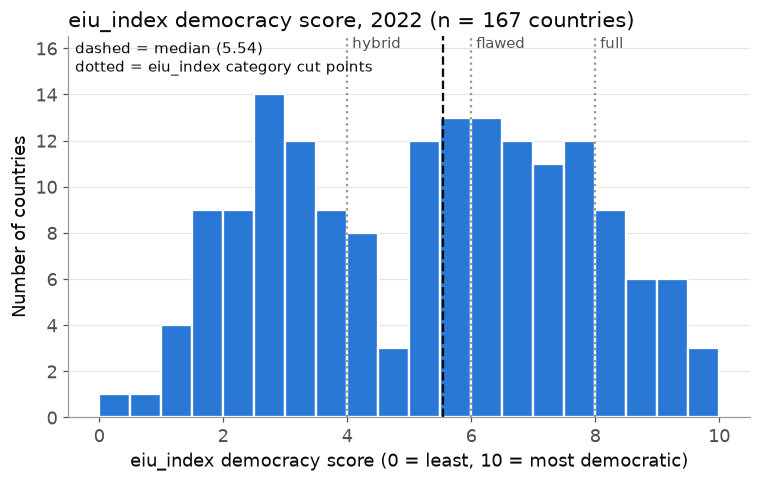

In [29]:
summarize(latest["Democracy score"], "score 2022")
print("lowest:", latest.sort("Democracy score").select("Entity", "Democracy score").head(3).rows())
print("highest:", latest.sort("Democracy score", descending=True).select("Entity", "Democracy score").head(3).rows())
print("countries per 1-point bin:", latest.with_columns(pl.col("Democracy score").floor().clip(0, 9).alias("bin")).group_by("bin").agg(pl.len()).sort("bin").rows())

fig, ax = plt.subplots()
ax.hist(latest["Democracy score"].to_list(), bins=[i / 2 for i in range(21)], color=BLUE, edgecolor="white", linewidth=1.5)
for cut, label in [(4, "hybrid"), (6, "flawed"), (8, "full")]:
    ax.axvline(cut, color=GRAY, linestyle=":", linewidth=1.5)
    ax.text(cut + 0.08, 1, label, transform=ax.get_xaxis_transform(), va="top", color=MUTED, fontsize=10)
ax.axvline(latest["Democracy score"].median(), color=INK, linestyle="--", linewidth=1.5)
ax.text(0.01, 0.99, f"dashed = median ({latest['Democracy score'].median():.2f})\ndotted = eiu_index category cut points",
        transform=ax.transAxes, va="top", ha="left", fontsize=10, color=INK)
ax.margins(y=0.18)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="x", visible=False)
ax.set_xlabel("eiu_index democracy score (0 = least, 10 = most democratic)")
ax.set_ylabel("Number of countries")
ax.set_title(f"eiu_index democracy score, 2022 (n = {latest.height} countries)", loc="left")
save(fig, "d1_score_2022")
plt.show()

**Shape:** a very wide spread (SD 2.38, IQR 3.12 to 7.13) across almost the whole 0 to 10 range. The center is median 5.54, mean 5.29, and the skew is about 0 (-0.04). It isn't one bell, though. There's a cluster of authoritarian scores from 2 to 4 (44 countries), a thin middle from 4 to 5 (11 countries), and a bigger cluster from 5 to 8 (73 countries). Afghanistan (0.32), Myanmar (0.74), and North Korea (1.08) are at the bottom, and Norway (9.81) is at the top. No point is an outlier by the 1.5 × IQR rule.

**Why it matters:** with two clusters and a gap in between, "the average country" isn't meaningful. Comparing groups (categories or regions) will be more honest for RQ1 than averages.

### 3.2 EIU category, 2022

shape: (4, 2)
┌──────────────────┬───────────┐
│ category         ┆ countries │
│ ---              ┆ ---       │
│ enum             ┆ u32       │
╞══════════════════╪═══════════╡
│ Authoritarian    ┆ 59        │
│ Hybrid regime    ┆ 36        │
│ Flawed democracy ┆ 48        │
│ Full democracy   ┆ 24        │
└──────────────────┴───────────┘


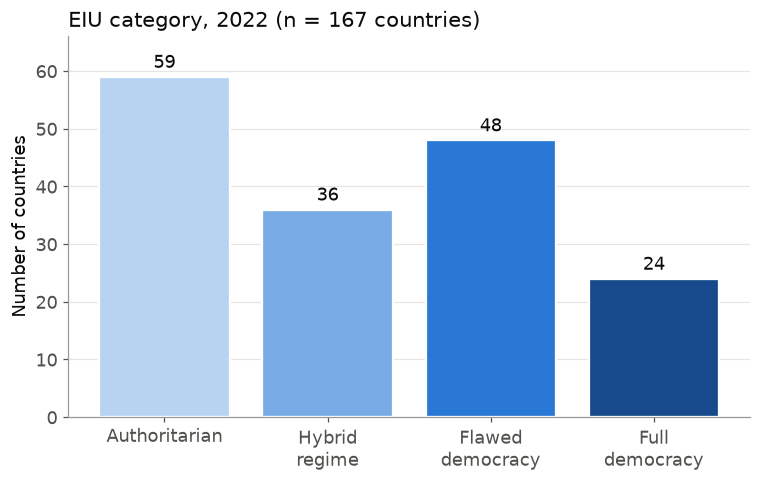

In [30]:
category_counts = latest.group_by("category").agg(pl.len().alias("countries")).sort("category")
print(category_counts)

fig, ax = plt.subplots()
shades = ["#b7d3f2", "#79abe6", "#2a78d6", "#174a8c"]  # one hue, light to dark, because the categories are ordered
labels = [c.replace(" ", "\n", 1) for c in category_counts["category"].cast(pl.String).to_list()]
bars = ax.bar(labels, category_counts["countries"].to_list(), color=shades, edgecolor="white", linewidth=1.5)
ax.bar_label(bars, padding=3, color=INK, fontsize=12)
ax.margins(y=0.12)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Number of countries")
ax.set_title(f"EIU category, 2022 (n = {latest.height} countries)", loc="left")
save(fig, "d2_category_2022")
plt.show()

**Shape:** this is an ordered category, so it gets a bar chart. **Authoritarian is the most common category (59)**, followed by flawed democracy (48), hybrid regime (36), and full democracy (24). Only about 14% of countries are full democracies, and 95 of 167 (57%) fall below the "flawed democracy" line. These counts match the totals EIU itself reported for 2022, which is a good sign the file is complete.

**Why it matters:** for RQ1, the categories give us four groups to compare HDI across (I do that in 4.2), and the groups are big enough to do it (full democracies are the smallest with 24, or 23 after the HDI join).

### 3.3 Year-to-year change in score

one-year change: n=2152  mean=-0.018  median=0.000  sd=0.237  IQR=-0.070 to 0.050  min=-2.530  max=2.740  skew=0.17
exactly 0: 741 | bigger than 1 point either way: 18
biggest drops: [('Afghanistan', 2021, -2.53), ('Myanmar', 2021, -2.02), ('Libya', 2015, -1.55), ('Niger', 2023, -1.36)]
biggest gains: [('Tunisia', 2011, 2.74), ('Fiji', 2014, 2.0), ('Thailand', 2019, 1.69), ('Libya', 2011, 1.61)]


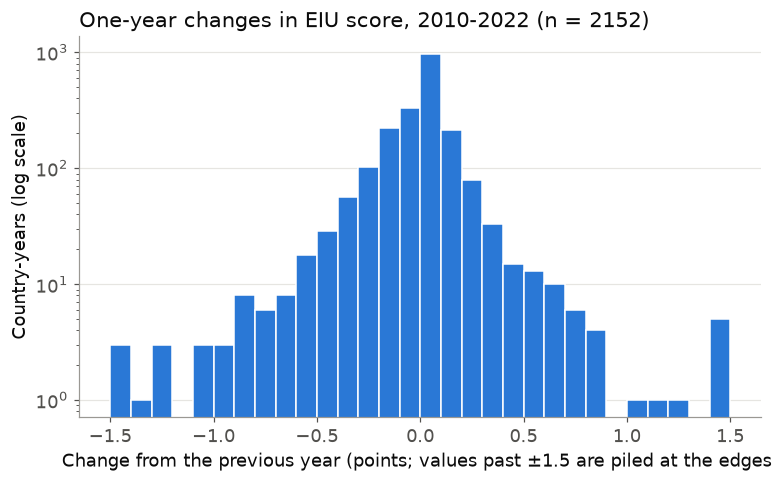

In [31]:
summarize(annual["change"], "one-year change")
print("exactly 0:", annual.filter(pl.col("change") == 0).height, "| bigger than 1 point either way:", annual.filter(pl.col("change").abs() > 1).height)
print("biggest drops:", annual.sort("change").select("Entity", "Year", pl.col("change").round(2)).head(4).rows())
print("biggest gains:", annual.sort("change", descending=True).select("Entity", "Year", pl.col("change").round(2)).head(4).rows())

fig, ax = plt.subplots()
clipped = annual["change"].clip(-1.5, 1.5)
ax.hist(clipped.to_list(), bins=[-1.5 + i * 0.1 for i in range(31)], color=BLUE, edgecolor="white", linewidth=1)
ax.set_yscale("log")
ax.set_xlabel("Change from the previous year (points; values past ±1.5 are piled at the edges)")
ax.set_ylabel("Country-years (log scale)")
ax.grid(axis="x", visible=False)
ax.set_title(f"One-year changes in EIU score, 2010-2022 (n = {annual.height})", loc="left")
save(fig, "d3_annual_change")
plt.show()

**Shape:** a huge spike at 0, since 33.9% of one-year changes are exactly zero. Around it the distribution is narrow (IQR -0.07 to 0.05, median 0) with **long tails**, so I used a log scale to make the rare big moves visible. Only 16 of 2,004 changes are bigger than 1 point. The biggest are Afghanistan's 2021 drop (-2.53), Myanmar's 2021 drop (-2.02), and Tunisia's 2011 jump (+2.74), which are a takeover, a coup, and a revolution. The mean is slightly negative (-0.014), so scores drift down a little over time.

**Why it matters:** most of the "action" for RQ2 is in a small number of big jumps that line up with real events. A model that predicts change will mostly be predicting zero, so we should probably focus on the big moves.

## 4. Relationships

Four plots. 4.1 uses the region rows from this file, and 4.2 and 4.3 use the join with the HDI file.

### 4.1 Democracy over time by continent

World: [(2006, 5.52), (2008, 5.55), (2010, 5.46), (2011, 5.49), (2012, 5.52), (2013, 5.53), (2014, 5.55), (2015, 5.55), (2016, 5.52), (2017, 5.48), (2018, 5.48), (2019, 5.44), (2020, 5.37), (2021, 5.28), (2022, 5.29), (2023, 5.69)]
Europe: 7.75 (2006) -> 7.54 (2022), change -0.21
Oceania: 7.58 (2006) -> 7.46 (2022), change -0.11
South America: 6.52 (2006) -> 6.11 (2022), change -0.41
North America: 6.57 (2006) -> 5.67 (2022), change -0.89
Asia: 4.38 (2006) -> 4.96 (2022), change +0.58
Africa: 4.11 (2006) -> 4.34 (2022), change +0.23


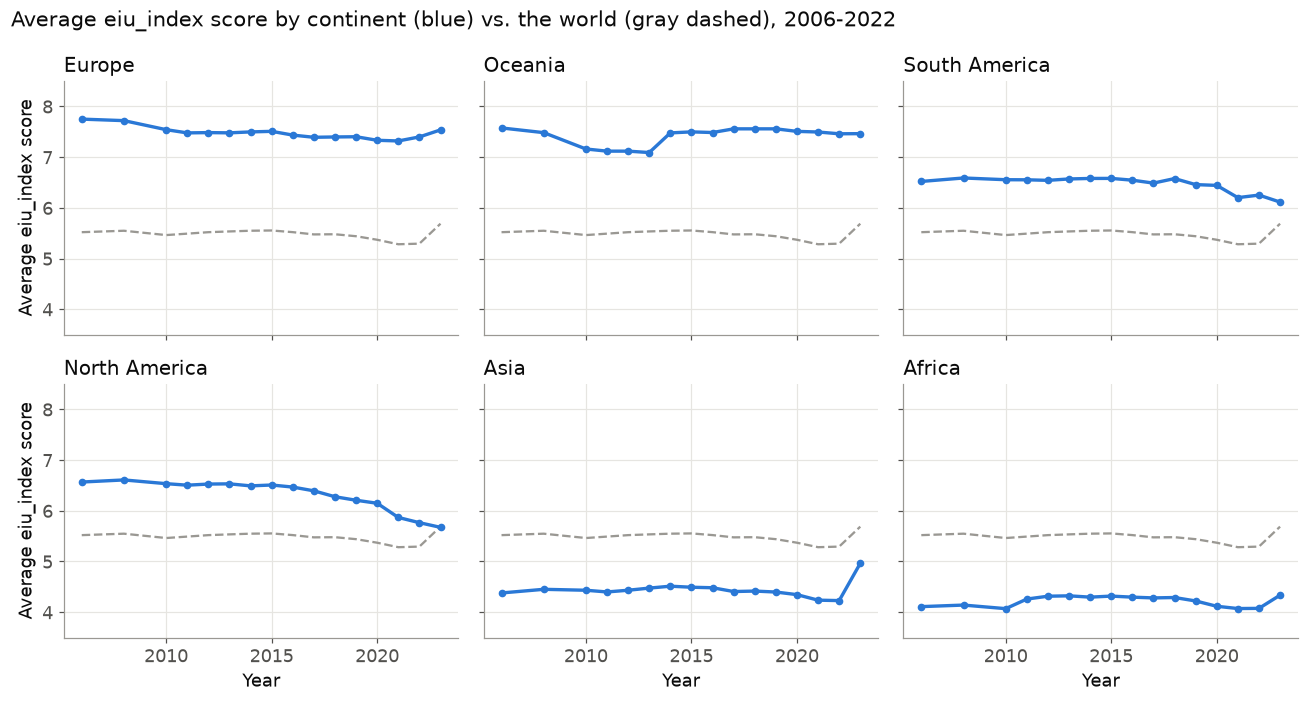

In [33]:
CONTINENTS = ["Europe", "Oceania", "South America", "North America", "Asia", "Africa"]
world = regions.filter(pl.col("Entity") == "World").sort("Year")
print("World:", world.select("Year", pl.col("Democracy score").round(2)).rows())
for name in CONTINENTS:
    s = regions.filter(pl.col("Entity") == name).sort("Year")["Democracy score"]
    print(f"{name}: {s[0]:.2f} (2006) -> {s[-1]:.2f} (2022), change {s[-1] - s[0]:+.2f}")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
for ax, name in zip(axes.flat, CONTINENTS):
    s = regions.filter(pl.col("Entity") == name).sort("Year")
    ax.plot(world["Year"].to_list(), world["Democracy score"].to_list(), color=GRAY, linestyle="--", linewidth=1.5)
    ax.plot(s["Year"].to_list(), s["Democracy score"].to_list(), color=BLUE, linewidth=2.2, marker="o", markersize=4)
    ax.set_title(name, loc="left", fontsize=13)
    ax.set_ylim(3.5, 8.5)
for ax in axes[1]:
    ax.set_xlabel("Year")
for ax in axes[:, 0]:
    ax.set_ylabel("Average eiu_index score")
fig.suptitle("Average eiu_index score by continent (blue) vs. the world (gray dashed), 2006-2022", x=0.01, ha="left", fontsize=14)
fig.tight_layout()
save(fig, "r1_continents_over_time")
plt.show()

**What it shows:** the world average climbs a little to a peak of 5.55 in 2015, then falls to 5.29 by 2022, with the steepest drop between 2019 and 2021. Every continent ends lower than it started. **North America falls the most (6.57 to 5.76)**, then South America (-0.27), Europe (-0.35), Asia (-0.15), Oceania (-0.12), and Africa, which is almost flat (4.11 to 4.07). The gaps between continents are much bigger than any change over time: Europe and Oceania stay around 7.5, while Africa and Asia stay around 4 to 4.5.

**So what:** this is the "across regions" part of RQ1. Region explains a lot of the variation in democracy, so any democracy-HDI link could partly be a region effect. The overall decline was expected, since the mid-2010s "democratic recession" is well known. North America falling the most was **unexpected**. OWID's "North America" includes Central America and the Caribbean, so countries like Nicaragua (-3.18) are probably driving it, not the US or Canada.

**What next:** split North America into US and Canada vs. Central America and the Caribbean. Also, these continent rows are unweighted averages (each country counts the same), so check whether a population-weighted version tells the same story.

### 4.4 Who backslid? Change from 2006 to 2022 vs. starting score

declined: 99 | improved: 66 | unchanged: 2 | median change: -0.17
r(starting score, change) = -0.07
shape: (4, 5)
┌──────────────────┬─────┬───────────────┬─────────────────────┬──────────┐
│ category_2006    ┆ n   ┆ median change ┆ mean size of change ┆ declined │
│ ---              ┆ --- ┆ ---           ┆ ---                 ┆ ---      │
│ enum             ┆ u32 ┆ f64           ┆ f64                 ┆ u32      │
╞══════════════════╪═════╪═══════════════╪═════════════════════╪══════════╡
│ Authoritarian    ┆ 55  ┆ 0.02          ┆ 0.74                ┆ 27       │
│ Hybrid regime    ┆ 33  ┆ -0.12         ┆ 1.11                ┆ 20       │
│ Flawed democracy ┆ 53  ┆ -0.21         ┆ 0.51                ┆ 36       │
│ Full democracy   ┆ 26  ┆ -0.19         ┆ 0.28                ┆ 16       │
└──────────────────┴─────┴───────────────┴─────────────────────┴──────────┘
biggest declines: [('Venezuela', -3.19), ('Nicaragua', -3.18), ('Mali', -2.76), ('Afghanistan', -2.74), ('Russia', -2.74)]
big

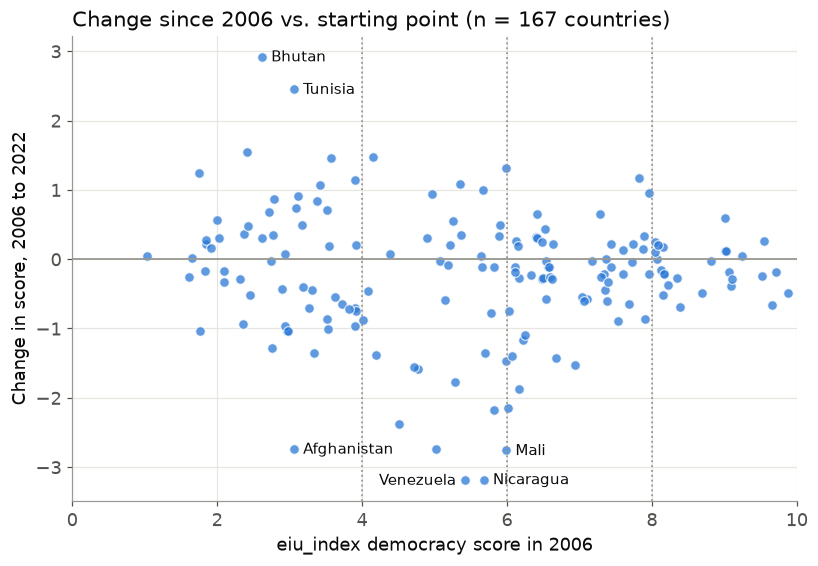

In [34]:
first_last = (
    countries.filter(pl.col("Year").is_in([2006, 2022]))
    .pivot(on="Year", index=["Entity", "Code"], values="Democracy score")
    .rename({"2006": "score_2006", "2022": "score_2022"})
    .with_columns((pl.col("score_2022") - pl.col("score_2006")).alias("change"))
    .join(countries.filter(pl.col("Year") == 2006).select("Entity", pl.col("category").alias("category_2006")), on="Entity")
)
print("declined:", first_last.filter(pl.col("change") < 0).height, "| improved:", first_last.filter(pl.col("change") > 0).height,
      "| unchanged:", first_last.filter(pl.col("change") == 0).height, "| median change:", round(first_last["change"].median(), 2))
print(f"r(starting score, change) = {first_last.select(pl.corr('score_2006', 'change')).item():.2f}")
print(first_last.group_by("category_2006").agg(
    pl.len().alias("n"),
    pl.col("change").median().round(2).alias("median change"),
    pl.col("change").abs().mean().round(2).alias("mean size of change"),
    (pl.col("change") < 0).sum().alias("declined"),
).sort("category_2006"))
print("biggest declines:", first_last.sort("change").select("Entity", pl.col("change").round(2)).head(5).rows())
print("biggest gains:", first_last.sort("change", descending=True).select("Entity", pl.col("change").round(2)).head(3).rows())

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.axhline(0, color=GRAY, linewidth=1.2)
for cut in (4, 6, 8):
    ax.axvline(cut, color=GRAY, linestyle=":", linewidth=1.2)
ax.scatter(first_last["score_2006"].to_list(), first_last["change"].to_list(), s=40, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
for row in pl.concat([first_last.sort("change").head(4), first_last.sort("change", descending=True).head(2)]).iter_rows(named=True):
    left = row["Entity"] == "Venezuela"  # sits right next to Nicaragua, so label it on the other side
    ax.annotate(row["Entity"], (row["score_2006"], row["change"]), xytext=(-6 if left else 6, -3), textcoords="offset points",
                ha="right" if left else "left", fontsize=10, color=INK)
ax.set_xlim(0, 10)
ax.set_xlabel("eiu_index democracy score in 2006")
ax.set_ylabel("Change in score, 2006 to 2022")
ax.set_title(f"Change since 2006 vs. starting point (n = {first_last.height} countries)", loc="left")
save(fig, "r4_change_vs_start")
plt.show()

**What it shows:** more countries declined (99) than improved (66) between 2006 and 2022, with a median change of -0.17. The starting score barely predicts the direction of change (r = -0.07), but it does predict **how much a country moves**. Countries that started as hybrid regimes moved the most (average size of change 1.11 points), while full democracies barely moved (0.28). The biggest declines are Venezuela, Nicaragua, Mali, Afghanistan, and Russia, and four of those five started as hybrid regimes. The biggest gains are Bhutan and Tunisia.

**So what:** this is the outcome RQ2 wants to predict ("shifts or regressions in democracy scores"). Backsliding is common, and it's concentrated in the unstable middle, not in established democracies. We expected a downward trend, but it was a surprise how flat the full democracies are compared with hybrid regimes.

**What next:** to actually predict these drops we need cross-country election data with turnout and electoral systems. **Our `elections.csv` only has U.S. presidential results** (see below), so it can't be joined to this file. A dataset like International IDEA's Voter Turnout Database would cover it. We should also check whether the big drops happen right around election years.

## 5-6. Revised research questions

What the data changed:

- **RQ1 (revised):** *How strongly is a country's EIU democracy score related to its HDI and IHDI in 2022-2023, and does the relationship change at the "flawed democracy" threshold (score 6)?*
  - **Why:** the HDI file only has 2023, so this has to be a single-year comparison, not a trend. The relationship in 4.2 is a step, not a line. And 4.3 shows that inequality loss mostly tracks HDI, so the mediation test has to control for HDI.
- **RQ2 (proposed revision, needs group sign-off):** *Which countries and regions backslid between 2006 and 2022, and are hybrid regimes more volatile than established democracies?*
  - **Why:** `elections.csv` is U.S. presidential results from 1824 to 2024 (one row per candidate), not the national turnout and electoral-system data described in Checkpoint 3. It can't be joined to the EIU panel. If we find a cross-national turnout dataset, the original RQ2 can come back.

**Notes for the group:**

- `democracy-eiu.csv` and `democracy-index-eiu.csv` are the same EIU data (every country row matches exactly; the second file just adds 2023), and neither has sub-scores. As such, I believe we should keep `democracy_index` and update the Checkpoint 3 description. Since the two files cover the same data, this section does not cover the relationships between `democracy_index` and `IHDI`.
- Remove the World and continent rows before any country-level analysis (105 rows).